# Quantitative Research -- Part 2: Graphical Representations (revision)

*Revision material: Parts 1 and 2 revise the descriptive statistics that Parts 3–5 build on.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChrisW09/Quantitative-Research-Methods/blob/main/Part_2_Graphical_Representations/Part_2_Graphical_Representations.ipynb)

This notebook is the companion of the slide deck *Part 2: Graphical Representations*.
Its sections follow the slides: every method is shown with the same Python commands
as on the slides, and the outputs reproduce the numbers of the slides.
Run the cells from top to bottom. For the exercises, first try them yourself in the
*Your turn* cell, then look at the solution cell.

**Contents**

1. Empirical Cumulative Distribution Function
   - 1.1 Exercises
2. Histogram
   - 2.1 Exercises
3. Boxplot
   - 3.1 Exercises
4. Exercises
   - 4.1 Body Heights
   - 4.2 Café Chain (Exam Style)
5. Python Commands
6. Summary (with the key Python commands)

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.distributions.empirical_distribution import ECDF

pd.set_option("display.width", 120)

## 1 Empirical Cumulative Distribution Function

Running example: the **shoe sizes of the soccer team** ($n = 11$) from Part 1.

Slides: *Empirical CDF -- Construction* and *Frequency Table*.
Relative frequency $f_j = h_j / n$; cumulative relative frequency = running sum of the $f_j$.

*In words:* the cumulative relative frequency of a value is the share of players whose
shoe size is at most this value.

In [2]:
shoe = np.array([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39])
n = len(shoe)
values, h = np.unique(shoe, return_counts=True)
freq = pd.DataFrame({"abs": h, "rel": h / n, "cum": np.cumsum(h) / n}, index=values)
freq.index.name = "shoe size"
freq.round(4)       # rel 0.0909 0.1818 0.3636 ...; cum 0.0909 0.2727 0.6364 0.8182 0.9091 1

,abs,rel,cum
shoe size,,,
37,1,0.0909,0.0909
38,2,0.1818,0.2727
39,4,0.3636,0.6364
40,2,0.1818,0.8182
41,1,0.0909,0.9091
46,1,0.0909,1.0000


Slides: *Empirical CDF -- Definition* and *Empirical CDF in Python* (computing and evaluating).

$$F(x) = \sum_{x_i \le x} f(x_i) = \frac{\text{number of observations} \le x}{n}$$

*In words:* $F(x)$ is the share of observations that are **at most** $x$.

In [3]:
F = ECDF(shoe)           # F is a function of x
print(round(F(39), 4))   # value of the empirical CDF at x = 39: 0.6364 (= 7/11)

0.6364


Slides: *Empirical CDF -- Reading Off Quantiles* (also graphically).

$$x_p = F^{-1}(p) = \min\{x \mid F(x) \ge p\} = x_{(\lceil n \cdot p \rceil)}$$

*In words:* go up to the height $p$, move right until you hit the step function and read
off the $x$-value there. In Python this is `method="inverted_cdf"`.

In [4]:
print("F(38) =", round(F(38), 4), "| F(39) =", round(F(39), 4), "| F(40) =", round(F(40), 4))
print("positions ceil(n*p):", math.ceil(n * 0.5), math.ceil(n * 0.8))   # 6 and 9
np.quantile(shoe, [0.5, 0.8], method="inverted_cdf")                  # median 39, 80 % quantile 40

F(38) = 0.2727 | F(39) = 0.6364 | F(40) = 0.8182
positions ceil(n*p): 6 9


array([39, 40])

Slide: *Empirical CDF in Python* (plotting). `plt.ecdf` draws the step function
(matplotlib $\ge$ 3.8).

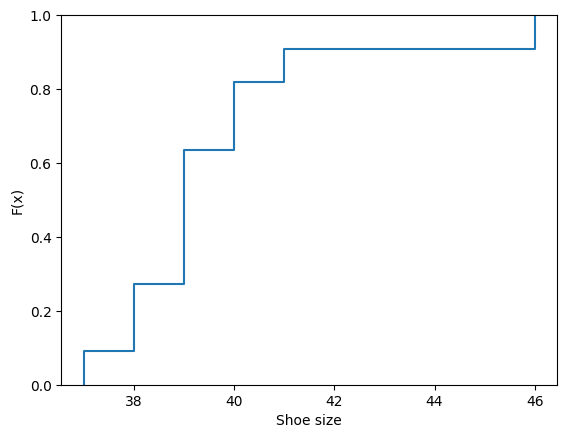

In [5]:
plt.ecdf(shoe)    # step function incl. vertical jumps (matplotlib >= 3.8)
plt.xlabel("Shoe size")
plt.ylabel("F(x)")
plt.show()

### 1.1 Exercises

#### Exercise -- Complaints per Day

An online shop records the number of customer complaints per day on $n = 10$ days:

2, 0, 3, 1, 2, 5, 1, 3, 2, 6

1. Set up the frequency table with absolute frequencies $h_j$, relative frequencies $f_j$
   and cumulative relative frequencies $F(x)$, and draw the empirical CDF.
2. Read off: What share of the days had at most 2 complaints? At most 4 complaints?
   More than 1 but at most 3 complaints?
3. Determine the median and the $80\,\%$ quantile from the empirical CDF.
4. Which Python commands check your results?

In [6]:
# Your turn: frequency table, shares, quantiles and plot
compl = np.array([2, 0, 3, 1, 2, 5, 1, 3, 2, 6])

**Solution**

Frequency table (slide *Solution (1/4)*): $F$ jumps up by $f_j$ at every observed value.

In [7]:
compl = np.array([2, 0, 3, 1, 2, 5, 1, 3, 2, 6])
print("Sorted:", np.sort(compl))
cv, ch = np.unique(compl, return_counts=True)
pd.DataFrame({"h_j": ch, "f_j": ch / len(compl), "F(x)": np.cumsum(ch) / len(compl)},
             index=cv).round(4)        # F: 0.1 0.3 0.6 0.8 0.9 1.0

Sorted: [0 1 1 2 2 2 3 3 5 6]


,h_j,f_j,F(x)
0,1,0.1,0.1
1,2,0.2,0.3
2,3,0.3,0.6
3,2,0.2,0.8
5,1,0.1,0.9
6,1,0.1,1.0


Shares, quantiles and plot (slides *Solution (2/4)* to *(4/4)*): $F(2) = 0.6$,
$F(4) = F(3) = 0.8$ (4 was never observed), $F(3) - F(1) = 0.5$; median $2$,
$80\,\%$ quantile $3$.

0.6 0.8 0.5
[2 3]


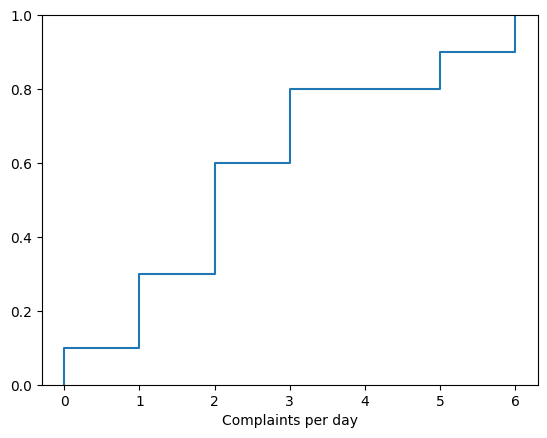

In [8]:
F = ECDF(compl)
print(F(2), F(4), F(3) - F(1))                                # shares
print(np.quantile(compl, [0.5, 0.8], method="inverted_cdf"))  # quantiles
plt.ecdf(compl)                                               # step function
plt.xlabel("Complaints per day")
plt.show()

## 2 Histogram

Slide: *Histogram*. The bar height is the **density**

$$\text{density}_j = \frac{f_j}{\Delta x_j} = \frac{\text{relative frequency of class } j}{\text{class width}},
\qquad \text{area}_j = \text{density}_j \cdot \Delta x_j = f_j .$$

*In words:* the **area** of each bar is the share of the observations in the class.
Classes are $[c_0, c_1], (c_1, c_2], \ldots, (c_{k-1}, c_k]$: open on the left, closed on
the right, only the first class is closed on both sides. `pd.cut(..., right=True,
include_lowest=True)` implements exactly this convention.

The small helper `class_table` collects the frequency table of the slides.

In [9]:
def class_table(x, breaks):
    # classes [b0,b1], (b1,b2], ... -> widths, absolute and relative frequencies, densities
    cls = pd.cut(x, breaks, right=True, include_lowest=True)
    h = pd.Series(cls).value_counts(sort=False)
    tab = pd.DataFrame({"width": np.diff(breaks), "abs": h.to_numpy()}, index=h.index.astype(str))
    tab["rel"] = tab["abs"] / len(x)                 # f_j
    tab["density"] = tab["rel"] / tab["width"]       # f_j / class width
    return tab

Slide: *Histogram -- Construction (Table)*, class width 2. pandas labels the closed first
class $[37, 39]$ as `(36.999, 39.0]`.

In [10]:
class_table(shoe, [37, 39, 41, 43, 45, 47]).round(4)    # densities 0.3182 0.1364 0 0 0.0455

,width,abs,rel,density
"(36.999, 39.0]",2,7,0.6364,0.3182
"(39.0, 41.0]",2,3,0.2727,0.1364
"(41.0, 43.0]",2,0,0.0000,0.0000
"(43.0, 45.0]",2,0,0.0000,0.0000
"(45.0, 47.0]",2,1,0.0909,0.0455


Slide: *Histogram -- Alternative Classes (Class Width 3)*.

In [11]:
class_table(shoe, [37, 40, 43, 46]).round(4)            # densities 0.2727 0.0303 0.0303

,width,abs,rel,density
"(36.999, 40.0]",3,9,0.8182,0.2727
"(40.0, 43.0]",3,1,0.0909,0.0303
"(43.0, 46.0]",3,1,0.0909,0.0303


Slide: *Histogram -- Unequal Class Widths*. *In words:* the wide class $(41, 46]$ holds as
many players as $(40, 41]$, but its bar is only a fifth as high.

In [12]:
tab_u = class_table(shoe, [37, 39, 40, 41, 46])
print(tab_u.round(4))                                   # densities 0.3182 0.1818 0.0909 0.0182
print("density (40,41] / density (41,46] =",
      round(tab_u["density"].iloc[2] / tab_u["density"].iloc[3], 4))   # 5.0

                width  abs     rel  density
(36.999, 39.0]      2    7  0.6364   0.3182
(39.0, 40.0]        1    2  0.1818   0.1818
(40.0, 41.0]        1    1  0.0909   0.0909
(41.0, 46.0]        5    1  0.0909   0.0182
density (40,41] / density (41,46] = 5.0


Slide: *Histogram -- Alternative Class Partition*: the same data with three class partitions.

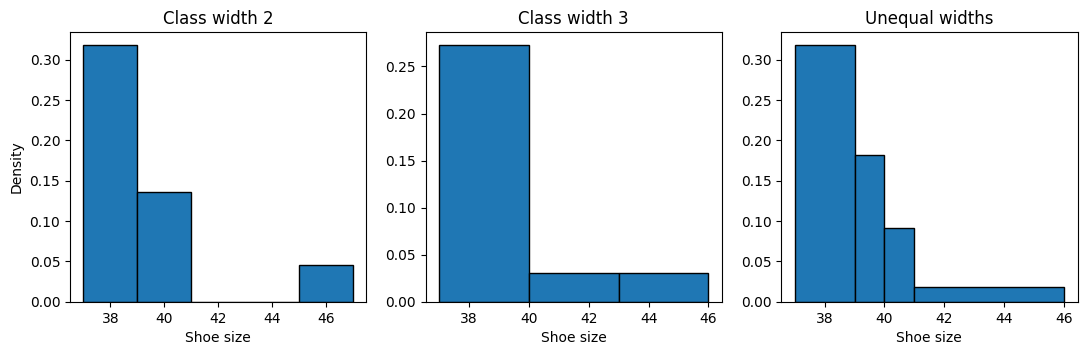

In [13]:
partitions = {"Class width 2": [37, 39, 41, 43, 45, 47], "Class width 3": [37, 40, 43, 46],
              "Unequal widths": [37, 39, 40, 41, 46]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (title, br) in zip(axes, partitions.items()):
    ax.bar(br[:-1], class_table(shoe, br)["density"], width=np.diff(br),
           align="edge", edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Shoe size")
axes[0].set_ylabel("Density")
plt.show()

#### Exercise -- Car Park

Histogram of the parking durations (in hours) of $n = 200$ tickets of a car park. The
classes are $[0,1]$, $(1,2]$, $(2,4]$, $(4,10]$. The bar labels (densities) of the first
three bars are $0.25$, $0.3$ and $0.15$; the label of the last bar is missing.

1. Determine the share $f_j$ and the number $h_j$ of tickets in each of the first three classes.
2. All bar areas add up to $1$. Use this to determine $f_4$, $h_4$ and the missing bar height.
3. The bar over $(1,2]$ is twice as high as the bar over $(2,4]$. Does $(1,2]$ contain twice
   as many tickets?
4. The first 2 hours are free of charge. What share of the tickets parked for free? How many
   tickets is that?

In [14]:
# Your turn: shares, numbers of tickets and the missing bar height
n_park = 200
breaks_p = [0, 1, 2, 4, 10]       # parking duration in hours
dens3 = [0.25, 0.3, 0.15]         # heights of the first three bars

**Solution**

Rule: area = density $\cdot$ class width $= f_j$, $h_j = f_j \cdot n$; all areas add up to 1.
The code of slide *Solution (3/3)*:

In [15]:
w = np.diff([0, 1, 2, 4, 10])          # class widths: 1 1 2 6
dens = np.array([0.25, 0.3, 0.15])     # heights of the first three bars
f = dens * w[:3]                       # areas = shares: 0.25 0.3 0.3
f4 = 1 - f.sum()                       # all areas add up to 1: f4 = 0.15
print(round(f4 / w[3], 4), np.round(np.r_[f, f4] * 200), round(f[0] + f[1], 4))

0.025 [50. 60. 60. 30.] 0.55


The complete table (slide *Solution (1/3)*) and the comparison of the two middle classes
(slide *Solution (2/3)*): both hold 60 tickets, but $(2,4]$ is twice as wide, so its bar
is only half as high.

In [16]:
f_all = np.r_[f, f4]
car = pd.DataFrame({"width": w, "density": f_all / w, "f_j": f_all,
                    "h_j": np.round(f_all * 200).astype(int)},
                   index=["[0,1]", "(1,2]", "(2,4]", "(4,10]"])
print(car.round(4))                                   # h_j 50 60 60 30, last density 0.025
print("height (1,2] / height (2,4] =", round(car["density"].iloc[1] / car["density"].iloc[2], 4))
print("free (at most 2 hours):", round(f[0] + f[1], 4), "->", round((f[0] + f[1]) * 200), "tickets")

        width  density   f_j  h_j
[0,1]       1    0.250  0.25   50
(1,2]       1    0.300  0.30   60
(2,4]       2    0.150  0.30   60
(4,10]      6    0.025  0.15   30
height (1,2] / height (2,4] = 2.0
free (at most 2 hours): 0.55 -> 110 tickets


Slide: *Histograms in Python* (class width 2): classes with `pd.cut`, bars with `plt.bar`.

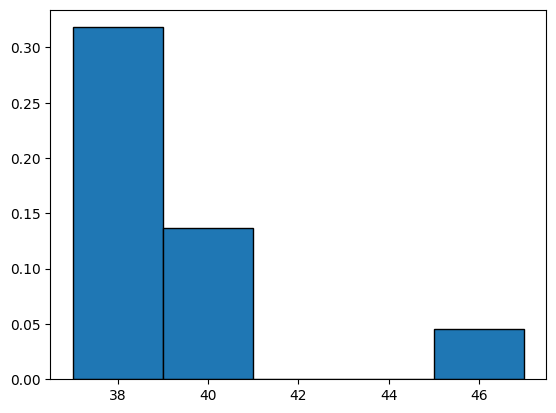

array([0.3182, 0.1364, 0.    , 0.    , 0.0455])

In [17]:
breaks = [37, 39, 41, 43, 45, 47]          # alternative: np.arange(37, 48, 2)
cls = pd.cut(shoe, breaks, right=True, include_lowest=True)  # [37,39], (39,41], ...
f = pd.Series(cls).value_counts(normalize=True, sort=False)   # rel. frequencies f_j
w = np.diff(breaks)                        # class widths
dens = f.to_numpy() / w                    # densities: 0.3182 0.1364 0 0 0.0455
plt.bar(breaks[:-1], dens, width=w, align="edge", edgecolor="black")
plt.show()
dens.round(4)

Same slide, unequal class widths: `breaks = [37, 39, 40, 41, 46]`, then the same lines.

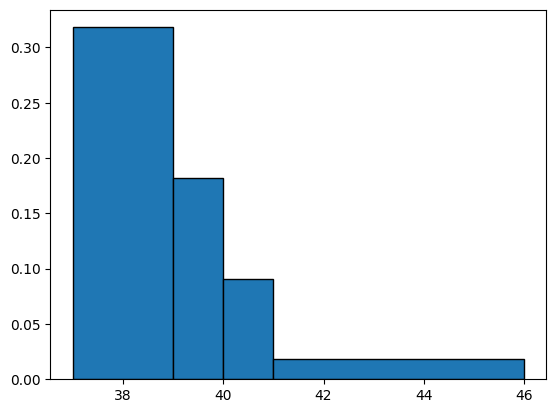

array([0.3182, 0.1818, 0.0909, 0.0182])

In [18]:
breaks = [37, 39, 40, 41, 46]
cls = pd.cut(shoe, breaks, right=True, include_lowest=True)
f = pd.Series(cls).value_counts(normalize=True, sort=False)
w = np.diff(breaks)
dens = f.to_numpy() / w                    # densities: 0.3182 0.1818 0.0909 0.0182
plt.bar(breaks[:-1], dens, width=w, align="edge", edgecolor="black")
plt.show()
dens.round(4)

Slide: *Histograms in Python -- Trap: Classes $[a,b)$*. `np.histogram` and `plt.hist` put a
boundary value into the class on its **right**: the four 39s land in $[39, 41)$ instead of
$[37, 39]$.

In [19]:
np.histogram(shoe, bins=[37, 39, 41, 43, 45, 47], density=True)[0].round(4)
# [0.1364 0.2727 0.0455 0. 0.0455]   <- not our densities!

array([0.1364, 0.2727, 0.0455, 0.    , 0.0455])

Slide: *Histograms in Python -- with Our Classes*: the function `density_hist` draws the
bars and returns the densities $f_j / \Delta x_j$.

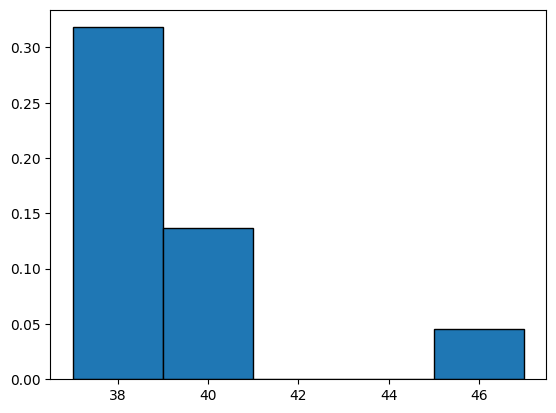

(36.999, 39.0]    0.3182
(39.0, 41.0]      0.1364
(41.0, 43.0]      0.0000
(43.0, 45.0]      0.0000
(45.0, 47.0]      0.0455
Name: proportion, dtype: float64

In [20]:
def density_hist(x, breaks):
    cls = pd.cut(x, breaks, right=True, include_lowest=True)
    f = pd.Series(cls).value_counts(normalize=True, sort=False)
    w = np.diff(breaks)                                  # class widths
    plt.bar(breaks[:-1], f / w, width=w, align="edge", edgecolor="black")
    return f / w                                         # densities f_j / w_j

d = density_hist(shoe, [37, 39, 41, 43, 45, 47])   # 0.3182 0.1364 0 0 0.0455
plt.show()
d.round(4)

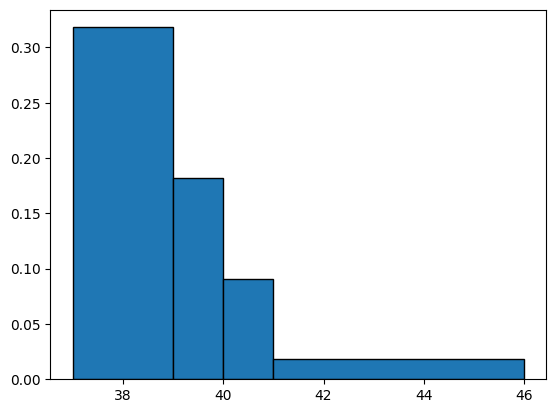

(36.999, 39.0]    0.3182
(39.0, 40.0]      0.1818
(40.0, 41.0]      0.0909
(41.0, 46.0]      0.0182
Name: proportion, dtype: float64

In [21]:
d = density_hist(shoe, [37, 39, 40, 41, 46])       # 0.3182 0.1818 0.0909 0.0182
plt.show()
d.round(4)

Slide: *Classified Frequencies in Python*.

In [22]:
breaks = [37, 39, 41, 43, 45, 47]          # class boundaries c0, c1, ..., ck
cls = pd.cut(shoe, breaks, right=True, include_lowest=True)
print(pd.Series(cls).value_counts(sort=False))                            # 7 3 0 0 1
print(pd.Series(cls).value_counts(normalize=True, sort=False).round(4))   # 0.6364 0.2727 0 0 0.0909

(36.999, 39.0]    7
(39.0, 41.0]      3
(41.0, 43.0]      0
(43.0, 45.0]      0
(45.0, 47.0]      1
Name: count, dtype: int64
(36.999, 39.0]    0.6364
(39.0, 41.0]      0.2727
(41.0, 43.0]      0.0000
(43.0, 45.0]      0.0000
(45.0, 47.0]      0.0909
Name: proportion, dtype: float64


### 2.1 Exercises

#### Exercise -- Histogram (Handball Team)

Shoe sizes of the handball team from Part 1 ($n = 13$):

40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39, 40, 42

1. Use the classes $[36,38], (38,40], (40,42], (42,44], (44,46]$ (class width 2). Assign the
   values to the classes and compute the absolute and relative frequencies. Careful with
   values that lie exactly on a class boundary!
2. Compute the densities and sketch the histogram.
3. With the classes of the worked example, $[37,39], (39,41], \ldots, (45,47]$, the same data
   give the counts $7, 4, 1, 0, 1$. Compare the shapes of the two histograms. What does this
   tell you about histograms?

In [23]:
# Your turn: class frequencies, densities and the histogram
handball = np.array([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39, 40, 42])

**Solution**

A value on a boundary belongs to the class *below* it (classes $(a,b]$, first class closed).

values on a class boundary: 7 of 13
                width  abs     rel  density
(35.999, 38.0]      2    3  0.2308   0.1154
(38.0, 40.0]        2    7  0.5385   0.2692
(40.0, 42.0]        2    2  0.1538   0.0769
(42.0, 44.0]        2    0  0.0000   0.0000
(44.0, 46.0]        2    1  0.0769   0.0385


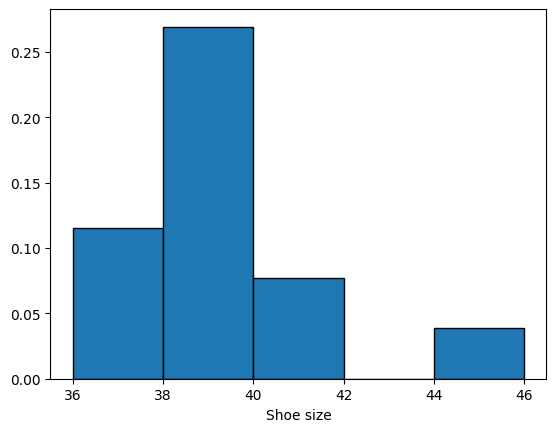

In [24]:
handball = np.array([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39, 40, 42])
breaks_hb = [36, 38, 40, 42, 44, 46]
print("values on a class boundary:", np.isin(handball, breaks_hb).sum(), "of", len(handball))  # 7
print(class_table(handball, breaks_hb).round(4))   # h_j 3 7 2 0 1; densities 0.1154 0.2692 0.0769 0 0.0385
density_hist(handball, breaks_hb)
plt.xlabel("Shoe size")
plt.show()

Task 3: with the classes of the worked example the bars *fall* from the first class on;
with the shifted classes they *rise to a peak* at $(38, 40]$. The shape of a histogram
depends on the choice of classes.

In [25]:
class_table(handball, [37, 39, 41, 43, 45, 47])["abs"].tolist()   # [7, 4, 1, 0, 1]

[7, 4, 1, 0, 1]

#### Exercise -- Mobile Phone Costs

A survey of $n = 10$ students gives the following monthly mobile phone costs (in EUR):

12, 25, 6, 38, 15, 60, 9, 19, 32, 18

The values are to be grouped into the classes $[0,10]$, $(10,20]$, $(20,40]$ and $(40,80]$.

1. Determine the absolute and relative frequencies of the classes.
2. Compute the class widths and the densities (bar heights) and draw the histogram.
3. Why must the bar height *not* equal the relative frequency here? Which class is the
   most densely populated?
4. Which Python commands reproduce the frequencies and densities?

In [26]:
# Your turn: frequencies, densities and the histogram
costs = np.array([12, 25, 6, 38, 15, 60, 9, 19, 32, 18])
breaks = [0, 10, 20, 40, 80]

**Solution**

Class frequencies and densities (slides *Solution (1/4)* and *(2/4)*).

In [27]:
costs = np.array([12, 25, 6, 38, 15, 60, 9, 19, 32, 18])
breaks = [0, 10, 20, 40, 80]
print("Sorted:", np.sort(costs))
tab_c = class_table(costs, breaks)
print(tab_c.round(4))                          # h_j 2 4 3 1; densities 0.02 0.04 0.015 0.0025
print("areas density * width:", (tab_c["density"] * tab_c["width"]).round(4).tolist())  # = f_j, sum 1

Sorted: [ 6  9 12 15 18 19 25 32 38 60]
                width  abs  rel  density
(-0.001, 10.0]     10    2  0.2   0.0200
(10.0, 20.0]       10    4  0.4   0.0400
(20.0, 40.0]       20    3  0.3   0.0150
(40.0, 80.0]       40    1  0.1   0.0025
areas density * width: [0.2, 0.4, 0.3, 0.1]


Interpretation (slide *Solution (3/4)*): with the height $f_j$ the wide class $(20, 40]$
would get the area $0.3 \cdot 20 = 6$, the class $(10, 20]$ only $0.4 \cdot 10 = 4$.
The most densely populated class is $(10, 20]$ with density $0.04$.

In [28]:
print("areas with height f_j (wrong!):", (tab_c["rel"] * tab_c["width"]).round(4).tolist())  # 2 4 6 4
print("most densely populated class:", tab_c["density"].idxmax(), tab_c["density"].max())

areas with height f_j (wrong!): [2.0, 4.0, 6.0, 4.0]
most densely populated class: (10.0, 20.0] 0.04


Python (slide *Solution (4/4)*).

[2 4 3 1] [0.02   0.04   0.015  0.0025]


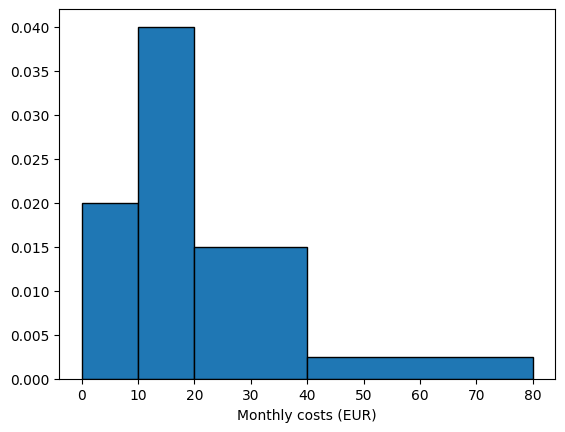

In [29]:
cls = pd.cut(costs, breaks, right=True, include_lowest=True)
h = pd.Series(cls).value_counts(sort=False).to_numpy()   # absolute frequencies
print(h, h / len(costs) / np.diff(breaks))               # h_j and densities
density_hist(costs, breaks)              # bars (function from "with Our Classes")
plt.xlabel("Monthly costs (EUR)")
plt.show()

## 3 Boxplot

Slides: *Boxplot -- Construction* and *Boxplot -- Construction (Quartiles)*. The building
blocks are the quartiles of Part 1 with the position rule

$$x_p = x_{(\lceil n \cdot p \rceil)} .$$

*In words:* sort the data, compute $n \cdot p$, round up, and take the value at this position.

In [30]:
xs = np.sort(shoe)
for p in (0.25, 0.5, 0.75):
    pos = math.ceil(n * p)
    print(f"p = {p:.2f}: n*p = {n * p:.2f} -> position {pos} -> value {xs[pos - 1]}")
np.quantile(shoe, [0.25, 0.5, 0.75], method="inverted_cdf")    # 38 39 40

p = 0.25: n*p = 2.75 -> position 3 -> value 38
p = 0.50: n*p = 5.50 -> position 6 -> value 39
p = 0.75: n*p = 8.25 -> position 9 -> value 40


array([38, 39, 40])

Slides: *Lower Whisker* and *Upper Whisker -- Computation / Step by Step* ($k = 1.5$):

$$\text{Whisker}_{\min} = \min\{x_i \mid x_i \ge x_{0.25} - k \cdot \text{IQR}\}, \qquad
\text{Whisker}_{\max} = \max\{x_i \mid x_i \le x_{0.75} + k \cdot \text{IQR}\}$$

*In words:* the whiskers end at the most extreme data values that still lie inside the
bounds; values beyond the bounds are outliers. (Commands as on slide *Python Commands:
Boxplot with Our Quartile Definition*.)

In [31]:
q1, med, q3 = np.quantile(shoe, [0.25, 0.5, 0.75], method="inverted_cdf")  # 38 39 40
iqr = q3 - q1                                    # IQR = 2
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # bounds: 35.0  43.0
inside = shoe[(shoe >= lo) & (shoe <= hi)]
whislo, whishi = inside.min(), inside.max()      # whiskers: 37  41
outliers = shoe[(shoe < lo) | (shoe > hi)]       # outlier: [46]
print(iqr, lo, hi, whislo, whishi, outliers)

2 35.0 43.0 37 41 [46]


Slides: *Boxplot* and *Boxplot -- with Labels*: drawing the boxplot from exactly these
statistics (`plt.boxplot` would interpolate the quartiles, see section 5).

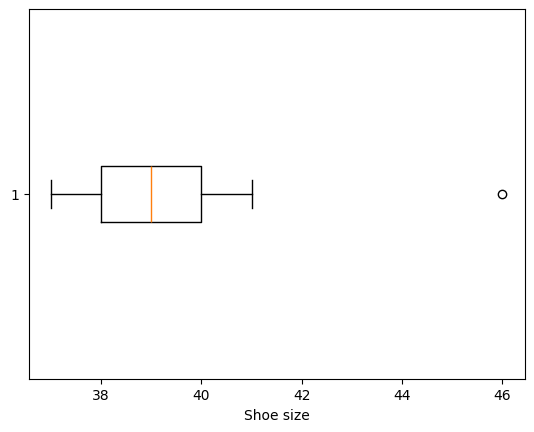

In [32]:
stats = dict(q1=q1, med=med, q3=q3, whislo=whislo, whishi=whishi, fliers=outliers)
plt.gca().bxp([stats], vert=False)
plt.xlabel("Shoe size")
plt.show()

#### Exercise -- Daily Revenues

The online shop from the exercise "Complaints per Day" also records its daily revenue
(in 1000 EUR) on the same $n = 10$ days:

| Day $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| Revenue $x_i$ | 15 | 18 | 12 | 22 | 17 | 13 | 14 | 20 | 17 | 4 |
| Complaints | 2 | 0 | 3 | 1 | 2 | 5 | 1 | 3 | 2 | 6 |

1. Sort the revenues and determine $x_{0.25}$, the median $\tilde{x}$ and $x_{0.75}$.
2. Compute the IQR and the bounds $x_{0.25} - 1.5 \cdot \text{IQR}$ and
   $x_{0.75} + 1.5 \cdot \text{IQR}$. Determine the lower and the upper whisker and
   possible outliers.
3. Draw the boxplot. Compare a possible outlier with the number of complaints on the same day.

In [33]:
# Your turn: quartiles, bounds, whiskers, outliers and the boxplot
rev = np.array([15, 18, 12, 22, 17, 13, 14, 20, 17, 4])        # days 1-10, 1000 EUR
compl = np.array([2, 0, 3, 1, 2, 5, 1, 3, 2, 6])

**Solution**

Position $\lceil n \cdot p \rceil$; if $n \cdot p$ is already an integer it is not rounded up
($10 \cdot 0.5 = 5 \to$ position 5). Note that `np.median` averages the 5th and 6th value.

In [34]:
rev = np.array([15, 18, 12, 22, 17, 13, 14, 20, 17, 4])
compl = np.array([2, 0, 3, 1, 2, 5, 1, 3, 2, 6])
print("Sorted:", np.sort(rev))
print("positions:", [math.ceil(len(rev) * p) for p in (0.25, 0.5, 0.75)])   # 3 5 8
print(np.quantile(rev, [0.25, 0.5, 0.75], method="inverted_cdf"), np.median(rev))  # [13 15 18] 16.0

Sorted: [ 4 12 13 14 15 17 17 18 20 22]
positions: [3, 5, 8]
[13 15 18] 16.0


IQR = 5 | 1.5 * IQR = 7.5 | bounds: 5.5 25.5
whiskers: 12 22 | outliers: [4]
outlier on day 10 with 6 complaints (maximum: 6 )


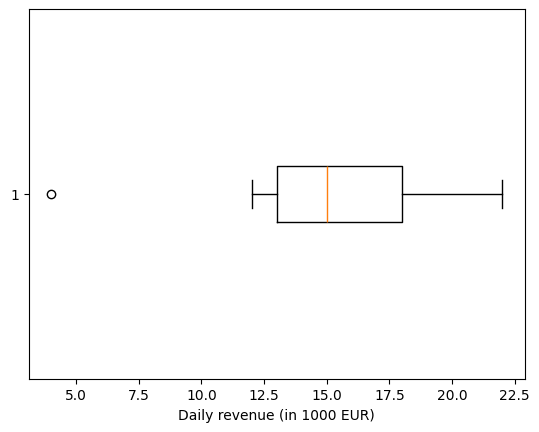

In [35]:
q1r, medr, q3r = np.quantile(rev, [0.25, 0.5, 0.75], method="inverted_cdf")
iqr_r = q3r - q1r                                     # 5
lo_r, hi_r = q1r - 1.5 * iqr_r, q3r + 1.5 * iqr_r     # 5.5 and 25.5
inside_r = rev[(rev >= lo_r) & (rev <= hi_r)]
out_r = rev[(rev < lo_r) | (rev > hi_r)]
print("IQR =", iqr_r, "| 1.5 * IQR =", 1.5 * iqr_r, "| bounds:", lo_r, hi_r)
print("whiskers:", inside_r.min(), inside_r.max(), "| outliers:", out_r)   # 12 22 [4]
day = np.flatnonzero(rev == out_r[0])[0] + 1
print("outlier on day", day, "with", compl[day - 1], "complaints (maximum:", compl.max(), ")")
plt.gca().bxp([dict(q1=q1r, med=medr, q3=q3r, whislo=inside_r.min(),
                    whishi=inside_r.max(), fliers=out_r)], vert=False)
plt.xlabel("Daily revenue (in 1000 EUR)")
plt.show()

Slides: *Boxplot -- Interpretation (1/3)* to *(3/3)*. Median in the middle of the box and
equally long whiskers indicate symmetry; for the shoe sizes the box and the whiskers are
symmetric, but the outlier $46 > 43$ makes the overall picture asymmetric.

In [36]:
print("median - Q1 =", med - q1, "| Q3 - median =", q3 - med)                    # 1 1
print("lower whisker length =", q1 - whislo, "| upper whisker length =", whishi - q3)   # 1 1

median - Q1 = 1 | Q3 - median = 1
lower whisker length = 1 | upper whisker length = 1


### 3.1 Exercises

#### Exercise -- Processing Times of Two Teams

Two service teams handle customer requests. For $n = 11$ requests each, the processing
time (in minutes) was recorded:

| Team | Processing times |
|---|---|
| Team A | 7, 4, 9, 6, 18, 8, 5, 10, 6, 9, 7 |
| Team B | 12, 8, 15, 5, 14, 10, 16, 8, 11, 14, 7 |

1. Team A: determine the quartiles, the IQR, the bounds $x_{0.25} - 1.5 \cdot \text{IQR}$
   and $x_{0.75} + 1.5 \cdot \text{IQR}$, the whiskers and possible outliers.
2. Carry out the same computations for team B.
3. Draw both boxplots above a common axis.
4. Compare median, IQR and outliers. What does the position of the median in the box say
   about skewness? Which team works faster and more consistently?

In [37]:
# Your turn: boxplot statistics of both teams and the two boxplots
team_a = np.array([7, 4, 9, 6, 18, 8, 5, 10, 6, 9, 7])
team_b = np.array([12, 8, 15, 5, 14, 10, 16, 8, 11, 14, 7])

**Solution**

The function `box_stats` of slide *Solution (5/5)* returns the course quartiles, whiskers
and outliers; the IQR and the bounds are printed in addition.

In [38]:
def box_stats(x, k=1.5):                    # course quartiles + 1.5 IQR rule
    q1, med, q3 = np.quantile(x, [0.25, 0.5, 0.75], method="inverted_cdf")
    lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    inside = x[(x >= lo) & (x <= hi)]
    return dict(q1=q1, med=med, q3=q3, whislo=inside.min(), whishi=inside.max(),
                fliers=x[(x < lo) | (x > hi)])

team_a = np.array([7, 4, 9, 6, 18, 8, 5, 10, 6, 9, 7])
team_b = np.array([12, 8, 15, 5, 14, 10, 16, 8, 11, 14, 7])
stats = [box_stats(team_a), box_stats(team_b)]
for name, s in zip(("A", "B"), stats):
    iqr_t = s["q3"] - s["q1"]
    print(f"Team {name}: whislo {s['whislo']}, q1 {s['q1']}, med {s['med']}, q3 {s['q3']}, "
          f"whishi {s['whishi']}, fliers {s['fliers']} | IQR {iqr_t}, "
          f"bounds {s['q1'] - 1.5 * iqr_t} / {s['q3'] + 1.5 * iqr_t}")
# A: 4 6 7 9 10 [18], IQR 3, bounds 1.5 / 13.5   B: 5 8 11 14 16 [], IQR 6, bounds -1.0 / 23.0

Team A: whislo 4, q1 6, med 7, q3 9, whishi 10, fliers [18] | IQR 3, bounds 1.5 / 13.5
Team B: whislo 5, q1 8, med 11, q3 14, whishi 16, fliers [] | IQR 6, bounds -1.0 / 23.0


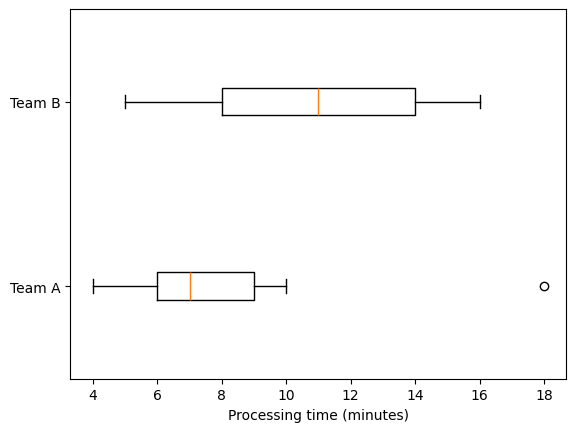

In [39]:
fig, ax = plt.subplots(); ax.bxp(stats, vert=False)   # boxplots, common axis
ax.set_yticks([1, 2], ["Team A", "Team B"])
ax.set_xlabel("Processing time (minutes)")
plt.show()

Comparison (slide *Solution (4/5)*): team A has the smaller median (7 vs. 11) and the
smaller IQR (3 vs. 6); its median lies in the left half of the box and its outlier on the
right $\to$ right-skewed. Team B is roughly symmetric.

In [40]:
for name, s in zip(("A", "B"), stats):
    print(f"Team {name}: median - Q1 = {s['med'] - s['q1']}, Q3 - median = {s['q3'] - s['med']}"
          f" | whisker lengths {s['q1'] - s['whislo']} and {s['whishi'] - s['q3']}")
# A: 1 vs 2 and whiskers 2, 1;  B: 3 vs 3 and whiskers 3, 2

Team A: median - Q1 = 1, Q3 - median = 2 | whisker lengths 2 and 1
Team B: median - Q1 = 3, Q3 - median = 3 | whisker lengths 3 and 2


## 4 Exercises

### 4.1 Body Heights

The body heights (in cm) of $n = 15$ persons are studied:

164, 162, 168, 198, 166, 166, 192, 160, 151, 175, 180, 160, 168, 175, 168

1. Compute the mean, median, quartiles and the $17\,\%$ quantile.
2. Compute the measures of dispersion: range, IQR, sample variance, standard deviation,
   coefficient of variation and normalised coefficient of variation.
3. Draw the empirical CDF, a histogram (class width 10 cm) and a boxplot.
4. Draw the empirical CDF for the classified data (class midpoints).

In [41]:
# Your turn: measures of location and dispersion, empirical CDF, histogram and boxplot
heights = np.array([164, 162, 168, 198, 166, 166, 192, 160, 151, 175,
                    180, 160, 168, 175, 168])

**Solution**

Frequency table (slide *The Data*) and measures of location (slides *Mean*, *Median and
Mode*, *Quartiles and Quantile*): $\bar{x} = \frac{1}{n}\sum x_i$, quantiles at position
$\lceil n \cdot p \rceil$.

In [42]:
heights = np.array([164, 162, 168, 198, 166, 166, 192, 160, 151, 175,
                    180, 160, 168, 175, 168])
m = len(heights)
print("Sorted:", np.sort(heights))
hv, hh = np.unique(heights, return_counts=True)
print(pd.DataFrame({"abs": hh, "rel": hh / m, "cum": np.cumsum(hh) / m}, index=hv).round(4))
print("sum =", heights.sum(), "| mean =", round(heights.mean(), 4))       # 2553, 170.2
print("mode:", pd.Series(heights).mode().tolist())                       # [168]
print("positions:", [math.ceil(m * p) for p in (0.17, 0.25, 0.5, 0.75)])  # 3 4 8 12
np.quantile(heights, [0.17, 0.25, 0.5, 0.75], method="inverted_cdf")      # 160 162 168 175

Sorted: [151 160 160 162 164 166 166 168 168 168 175 175 180 192 198]
     abs     rel     cum
151    1  0.0667  0.0667
160    2  0.1333  0.2000
162    1  0.0667  0.2667
164    1  0.0667  0.3333
166    2  0.1333  0.4667
168    3  0.2000  0.6667
175    2  0.1333  0.8000
180    1  0.0667  0.8667
192    1  0.0667  0.9333
198    1  0.0667  1.0000
sum = 2553 | mean = 170.2
mode: [168]
positions: [3, 4, 8, 12]


array([160, 162, 168, 175])

Measures of dispersion (slides *Range and IQR*, *Variance and Standard Deviation*,
*Coefficient of Variation*):
$s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$, $v = s / \bar{x}$, $v^* = v / \sqrt{n}$.

In [43]:
q = np.quantile(heights, [0.25, 0.75], method="inverted_cdf")
s2 = np.var(heights, ddof=1)
s = np.std(heights, ddof=1)
v = s / heights.mean()
print("range =", heights.max() - heights.min(), "| IQR =", q[1] - q[0])              # 47, 13
print("sum of squared deviations =", round(((heights - heights.mean()) ** 2).sum(), 2))  # 2122.4
print(f"s^2 = {s2:.2f}, s = {s:.4f}, v = {v:.4f}, v* = {v / np.sqrt(m):.4f}")          # 151.60 12.3126 0.0723 0.0187

range = 47 | IQR = 13
sum of squared deviations = 2122.4
s^2 = 151.60, s = 12.3126, v = 0.0723, v* = 0.0187


Whiskers (slide *Whisker Computation*): bounds $142.5$ and $194.5$, whiskers $151$ and
$192$, outlier $198$.

In [44]:
st_h = box_stats(heights)
iqr_h = st_h["q3"] - st_h["q1"]
print("bounds:", st_h["q1"] - 1.5 * iqr_h, st_h["q3"] + 1.5 * iqr_h)   # 142.5 194.5
print("whiskers:", st_h["whislo"], st_h["whishi"], "| outliers:", st_h["fliers"])

bounds: 142.5 194.5
whiskers: 151 192 | outliers: [198]


Graphics (slides *Empirical CDF*, *Histogram (Table)*, *Histogram*, *Boxplot*).
Boundary values: 160 (twice) belongs to $[150, 160]$ and 180 to $(170, 180]$.

                  width  abs     rel  density
(149.999, 160.0]     10    3  0.2000   0.0200
(160.0, 170.0]       10    7  0.4667   0.0467
(170.0, 180.0]       10    3  0.2000   0.0200
(180.0, 190.0]       10    0  0.0000   0.0000
(190.0, 200.0]       10    2  0.1333   0.0133


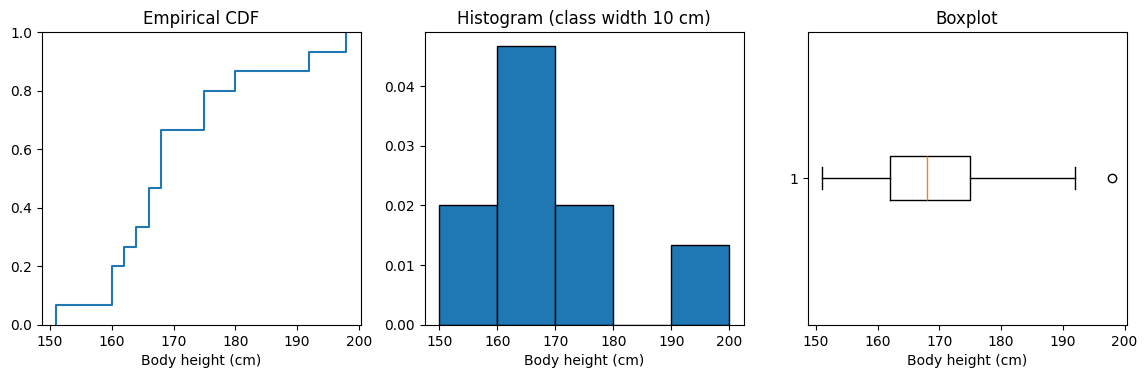

In [45]:
print(class_table(heights, [150, 160, 170, 180, 190, 200]).round(4))   # h_j 3 7 3 0 2
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
plt.sca(axes[0]); plt.ecdf(heights); axes[0].set_title("Empirical CDF")
plt.sca(axes[1]); density_hist(heights, [150, 160, 170, 180, 190, 200])
axes[1].set_title("Histogram (class width 10 cm)")
axes[2].bxp([st_h], vert=False); axes[2].set_title("Boxplot")
for ax in axes:
    ax.set_xlabel("Body height (cm)")
plt.show()

Classified data and Python (slides *Classified Data*, *Empirical CDF of the Classified Data*,
*Python*): all observations of a class are placed at the class midpoint $a_j$.

F at the midpoints: [0.2    0.6667 0.8667 0.8667 1.    ]


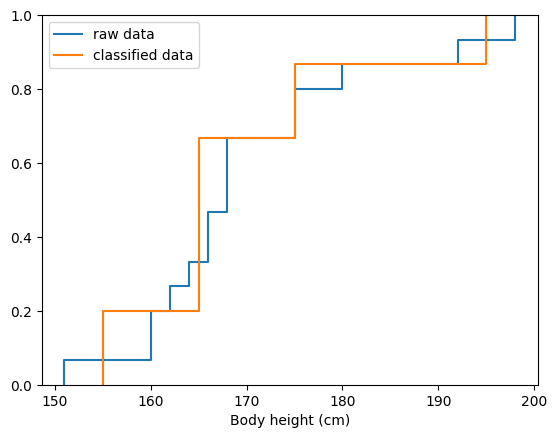

165


In [46]:
breaks = [150, 160, 170, 180, 190, 200]
cls = pd.cut(heights, breaks, right=True, include_lowest=True)
h = pd.Series(cls).value_counts(sort=False).to_numpy()   # 3 7 3 0 2
classified = np.repeat([155, 165, 175, 185, 195], h)     # each value -> class midpoint
print("F at the midpoints:", ECDF(classified)([155, 165, 175, 185, 195]).round(4))
plt.ecdf(heights, label="raw data")                      # raw-data ECDF
plt.ecdf(classified, label="classified data")            # classified ECDF, same axes
plt.legend(); plt.xlabel("Body height (cm)")
plt.show()
print(np.quantile(classified, 0.5, method="inverted_cdf"))   # 165 (exact median: 168)

Trap again (slide *Python*): `np.histogram` / `plt.hist` with classes $[a, b)$ count 160 and
180 in the next class.

In [47]:
np.histogram(heights, bins=[150, 160, 170, 180, 190, 200])[0]   # [1 9 2 1 2] instead of 3 7 3 0 2

array([1, 9, 2, 1, 2])

### 4.2 Café Chain (Exam Style)

**Part A** -- boxplot of the $n = 60$ daily revenues of a café (in 100 EUR): lower whisker
15, $Q_1 = 24$, median 28, $Q_3 = 36$, upper whisker 50, one outlier at 62.

1. Read off the median, $Q_1$, $Q_3$ and the whisker ends; compute the IQR.
2. On at least how many days was the revenue at most 2800 EUR?
3. Compute the fences. Why is 62 drawn as a point, and why does the upper whisker end at 50?
4. Assess the skewness. Is the mean above or below the median?

**Part B** -- histogram of the values (in EUR) of $n = 50$ orders; classes $[0,5]$,
$(5,10]$, $(10,20]$, $(20,40]$ with the densities $0.04$, $0.06$, $0.04$, $0.005$.

5. Determine the relative frequency and the number of orders of every class.
6. Which class contains the most orders? Is it the class with the highest bar?
7. What share of the orders is worth more than 10 EUR?

**Part C** -- repair times of the espresso machine (minutes): 2, 3, 3, 4, 5, 6, 26.

8. Compute the mean, the median and the trimmed mean (smallest and largest value removed).
   Is 26 an outlier by the $1.5 \cdot \text{IQR}$ rule? Which measure would you report?

In [48]:
# Your turn: the given boxplot values, histogram and repair times
cafe = dict(whislo=15, q1=24, med=28, q3=36, whishi=50, fliers=[62])   # in 100 EUR, n = 60
edges_o = np.array([0, 5, 10, 20, 40])                                 # order values in EUR
dens_o = np.array([0.04, 0.06, 0.04, 0.005])                           # n = 50 orders
rep = np.array([2, 3, 3, 4, 5, 6, 26])                                 # repair times (minutes)

**Solution**

Part A (slides *Solution (1/5)* to *(3/5)*): fences $Q_1 - 1.5 \cdot \text{IQR}$ and
$Q_3 + 1.5 \cdot \text{IQR}$; the median $x_{(\lceil 60 \cdot 0.5 \rceil)} = x_{(30)}$.

IQR = 12
median position: 30 -> at least 30 days with revenue <= 2800 EUR
fences: 6.0 54.0
median - Q1 = 4 | Q3 - median = 8 | whiskers 9 and 14


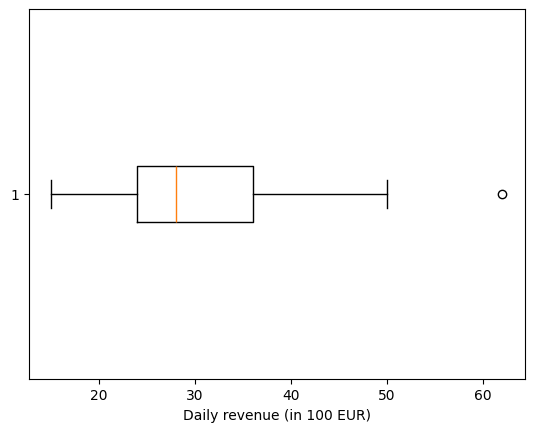

In [49]:
cafe = dict(whislo=15, q1=24, med=28, q3=36, whishi=50, fliers=[62])
iqr_c = cafe["q3"] - cafe["q1"]
print("IQR =", iqr_c)                                            # 12 (= 1200 EUR)
print("median position:", math.ceil(60 * 0.5), "-> at least 30 days with revenue <= 2800 EUR")
print("fences:", cafe["q1"] - 1.5 * iqr_c, cafe["q3"] + 1.5 * iqr_c)   # 6.0 54.0 -> 62 is an outlier
print("median - Q1 =", cafe["med"] - cafe["q1"], "| Q3 - median =", cafe["q3"] - cafe["med"],
      "| whiskers", cafe["q1"] - cafe["whislo"], "and", cafe["whishi"] - cafe["q3"])  # 4 8 | 9 14 -> right-skewed
plt.gca().bxp([cafe], vert=False)
plt.xlabel("Daily revenue (in 100 EUR)")
plt.show()

Part B (slide *Solution (4/5)*): area = density $\cdot$ class width $= f_j$, $h_j = f_j \cdot 50$.

In [50]:
edges_o = np.array([0, 5, 10, 20, 40])
dens_o = np.array([0.04, 0.06, 0.04, 0.005])
f_o = dens_o * np.diff(edges_o)                      # 0.2 0.3 0.4 0.1
orders = pd.DataFrame({"width": np.diff(edges_o), "density": dens_o, "f_j": f_o.round(4),
                       "h_j": np.round(f_o * 50).astype(int)},
                      index=["[0,5]", "(5,10]", "(10,20]", "(20,40]"])
print(orders)                                        # h_j 10 15 20 5
print("highest bar:", orders["density"].idxmax(), "| most orders:", orders["h_j"].idxmax())
print("share of orders > 10 EUR:", round(f_o[2:].sum(), 4))      # 0.5 (25 orders)

         width  density  f_j  h_j
[0,5]        5    0.040  0.2   10
(5,10]       5    0.060  0.3   15
(10,20]     10    0.040  0.4   20
(20,40]     20    0.005  0.1    5
highest bar: (5,10] | most orders: (10,20]
share of orders > 10 EUR: 0.5


Part C (slide *Solution (5/5)*): the outlier pulls the mean up; median and trimmed mean
are robust.

In [51]:
rep = np.array([2, 3, 3, 4, 5, 6, 26])
print(rep.mean(), np.quantile(rep, 0.5, method="inverted_cdf"), np.sort(rep)[1:-1].mean())  # 7.0 4 4.2
st_rep = box_stats(rep)
iqr_rep = st_rep["q3"] - st_rep["q1"]
print("Q1 =", st_rep["q1"], "| Q3 =", st_rep["q3"], "| upper fence =", st_rep["q3"] + 1.5 * iqr_rep,
      "| outliers:", st_rep["fliers"])                 # 3 6 10.5 [26]

7.0 4 4.2
Q1 = 3 | Q3 = 6 | upper fence = 10.5 | outliers: [26]


## 5 Python Commands

The command slides at the end of the deck, with the shoe sizes. Slide: *Python Commands:
Frequencies and Measures of Central Tendency*. `np.median` averages the two middle values
for even $n$ -- `method="inverted_cdf"` matches the course definition.

In [52]:
shoe = np.array([40, 39, 38, 41, 46, 39, 39, 38, 37, 40, 39])
tab = pd.Series(shoe).value_counts().sort_index()   # sorted by shoe size
print(tab)                                          # 37:1 38:2 39:4 40:2 41:1 46:1
print(round(np.mean(shoe), 4))                      # arithmetic mean: 39.6364
print(np.median(shoe))                              # 39.0
print(np.quantile(shoe, 0.8, method="inverted_cdf"))                 # 80% quantile: 40
print(np.quantile(shoe, [0.25, 0.5, 0.75], method="inverted_cdf"))   # quartiles: 38 39 40

37    1
38    2
39    4
40    2
41    1
46    1
Name: count, dtype: int64
39.6364
39.0
40
[38 39 40]


Slide: *Python Commands: Measures of Dispersion* (`ddof=1`: divide by $n - 1$).

In [53]:
print(round(np.var(shoe, ddof=1), 4))      # s^2 = 5.6545
print(round(np.std(shoe, ddof=1), 4))      # s   = 2.3779
v = np.std(shoe, ddof=1) / np.mean(shoe)   # 0.0600
vstar = v / np.sqrt(len(shoe))             # 0.0181
print(f"{v:.4f} {vstar:.4f}")
print(round(np.var(shoe), 4))              # without ddof=1: 5.1405 (divides by n)

5.6545
2.3779
0.0600 0.0181
5.1405


Slide: *Python Commands: Empirical CDF*.

0.6364
0.5455
[39 40]


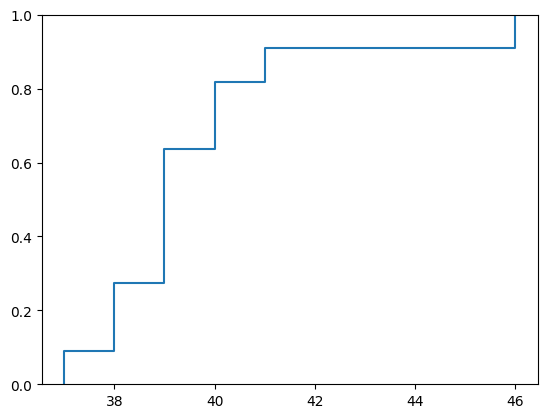

In [54]:
F = ECDF(shoe)
print(round(F(39), 4))           # value of the ECDF at x = 39: 0.6364
print(round(F(40) - F(38), 4))   # share in (38, 40], i.e. sizes 39 and 40: 0.5455 (= 6/11)
print(np.quantile(shoe, [0.5, 0.8], method="inverted_cdf"))   # min{x | F(x) >= p}: 39 40
plt.ecdf(shoe)  # step function with vertical jumps
plt.show()

Slides: *Python Commands: Histogram* and *Classified Frequencies* (`density_hist` from section 2).

[0.3182, 0.1364, 0.0, 0.0, 0.0455]


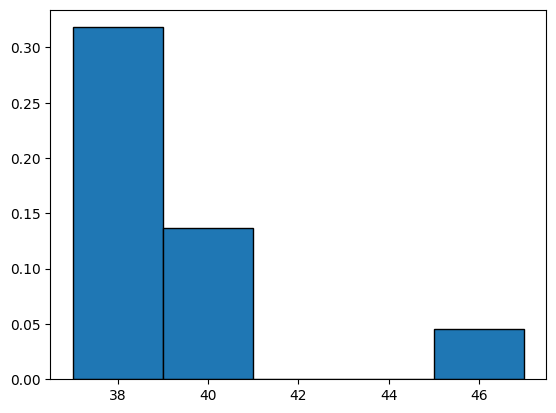

[0.3182, 0.1818, 0.0909, 0.0182]


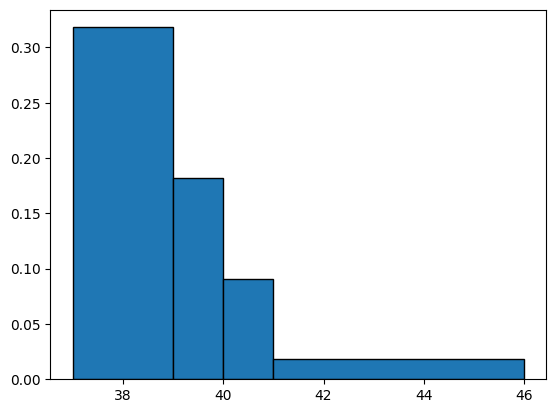

[7, 3, 0, 0, 1]
[0.6364, 0.2727, 0.0, 0.0, 0.0909]


In [55]:
print(density_hist(shoe, np.arange(37, 48, 2)).round(4).tolist())   # 0.3182 0.1364 0 0 0.0455
plt.show()
print(density_hist(shoe, [37, 39, 40, 41, 46]).round(4).tolist())   # 0.3182 0.1818 0.0909 0.0182
plt.show()
cls = pd.cut(shoe, bins=[37, 39, 41, 43, 45, 47], right=True, include_lowest=True)
print(pd.Series(cls).value_counts(sort=False).tolist())                            # 7 3 0 0 1
print(pd.Series(cls).value_counts(normalize=True, sort=False).round(4).tolist())   # 0.6364 0.2727 0 0 0.0909

Slide: *Python Commands: Boxplot*. `plt.boxplot` uses NumPy's default (linear
interpolation) for the quartiles, not the course definition.

[38.5 40. ]
[38 40]


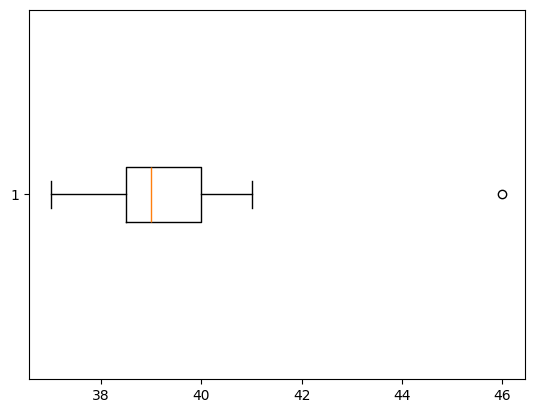

In [56]:
print(np.quantile(shoe, [0.25, 0.75]))                          # [38.5 40.] interpolated
print(np.quantile(shoe, [0.25, 0.75], method="inverted_cdf"))   # [38 40]    our definition
plt.boxplot(shoe, vert=False, whis=1.5)   # horizontal, whiskers at k = 1.5
plt.show()

Slides: *Python Commands: Boxplot with Our Quartile Definition* and *Boxplots of Several
Groups*.

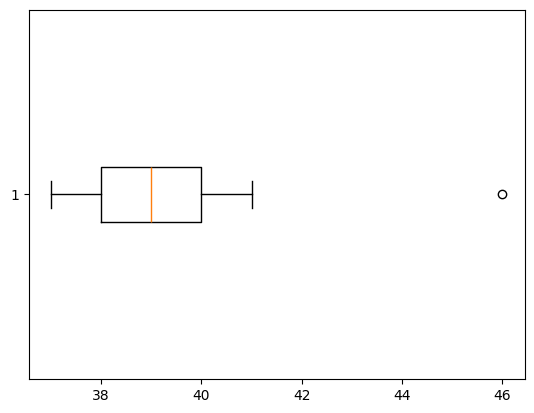

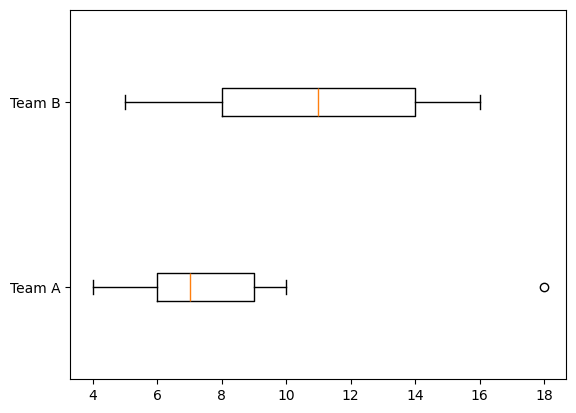

37 38 39 40 41 [46]


In [57]:
q1, med, q3 = np.quantile(shoe, [0.25, 0.5, 0.75], method="inverted_cdf")  # 38 39 40
iqr = q3 - q1                                    # IQR = 2
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr          # bounds: 35.0  43.0
inside = shoe[(shoe >= lo) & (shoe <= hi)]
whislo, whishi = inside.min(), inside.max()      # whiskers: 37  41
outliers = shoe[(shoe < lo) | (shoe > hi)]       # outlier: [46]
stats = dict(q1=q1, med=med, q3=q3, whislo=whislo, whishi=whishi, fliers=outliers)
plt.gca().bxp([stats], vert=False)
plt.show()

fig, ax = plt.subplots()                      # several boxplots, common axis
ax.bxp([box_stats(team_a), box_stats(team_b)], vert=False)
ax.set_yticks([1, 2], ["Team A", "Team B"])    # labels of the groups
plt.show()
st = box_stats(shoe)                          # reproduces the shoe-size boxplot
print(st["whislo"], st["q1"], st["med"], st["q3"], st["whishi"], st["fliers"])   # 37 38 39 40 41 [46]

## 6 Summary

| Question | Graphic | Read off |
|---|---|---|
| What share of the values is at most $x$? Up to which value lie at least $p \cdot 100\,\%$ of them? | Empirical CDF | $F(x)$, $F(b) - F(a)$, $x_p = \min\{x \mid F(x) \ge p\}$ |
| What does the distribution look like (peaks, gaps, tails)? | Histogram | height = density $f_j/\Delta x_j$, area = share $f_j$ |
| Centre, spread, skewness, outliers -- and comparison of groups? | Boxplot | $Q_1$, $\tilde{x}$, $Q_3$, IQR, whisker ends, points beyond the fences |

Course conventions: quantiles $x_{(\lceil n \cdot p \rceil)}$ and classes $(a, b]$ with the
first class closed -- in Python `method="inverted_cdf"` and `pd.cut(..., include_lowest=True)`.

**Key Python commands**

| Task | Command |
|---|---|
| Empirical CDF as a function | `F = ECDF(x)`; `F(39)`; `F(b) - F(a)` |
| Plot the empirical CDF | `plt.ecdf(x)` |
| Quantiles (course rule) | `np.quantile(x, p, method="inverted_cdf")` |
| Classes $(a,b]$, first class closed | `pd.cut(x, breaks, right=True, include_lowest=True)` |
| Classified frequencies | `pd.Series(cls).value_counts(sort=False)`, `normalize=True` for $f_j$ |
| Densities and bars | `f / np.diff(breaks)`; `plt.bar(breaks[:-1], dens, width=w, align="edge")` |
| Avoid for our classes | `plt.hist`, `np.histogram` (classes $[a,b)$) |
| Boxplot statistics (course quartiles) | `box_stats(x)` (section 3.1) |
| Draw boxplots from given statistics | `ax.bxp([stats], vert=False)` |
| Standard boxplot (interpolated quartiles) | `plt.boxplot(x, vert=False, whis=1.5)` |